# TraCE action recognition: prediction, contributions, intervention

This notebook only calls functions of the `src` package. It needs a released AR bundle (`checkpoints/ar/<dataset>`) and cached VideoMAE features of the validation split (see the Checkpoints section of the README). Set `VIDEO_ROOT` to draw trajectory-concept medoids on their source videos (optional).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('..'))
import torch
from src.ar import TraCEAR
from src.ar.data import read_annotation, load_features
from src.explain.intervention import ar_removal
from src.explain.visualize import plot_contributions, plot_removal_curve

DATASET = 'chiral_ssv2'
BUNDLE = f'../checkpoints/ar/{DATASET}'
FEATURES = f'../features/ar/{DATASET}/val_videomae.pt'
ANNOTATION = f'../annotations/{DATASET}/val.csv'
TRAJ_CONCEPTS = f'../checkpoints/trajectory_concepts/{DATASET}'
VIDEO_ROOT = os.environ.get('TRACE_VIDEO_ROOT')  # optional, for medoid drawing

## Load the model and evaluate on cached features

In [2]:
model = TraCEAR.load(BUNDLE)
print(model.vocab.group_sizes(), len(model.classes), 'classes')
videos, labels = read_annotation(ANNOTATION)
x = load_features(FEATURES, videos)
y = torch.tensor(labels)
print('top-1 accuracy: %.2f%%' % (100 * (model.predict(x) == y).float().mean()))

{'trajectory': 154, 'object': 404, 'scene': 286} 32 classes
top-1 accuracy: 84.20%


## Explain one prediction

Contribution of concept m to class k is `z_m * W[k, m]` on the standardized activation `z`. Contributions plus the class bias reconstruct the logit exactly.

video: 54495.mp4
ground truth: Pulling [something] from left to right | prediction: Pushing [something] from left to right
sum of contributions 6.9114 + bias 0.9115 = 7.8229 (logit 7.8229)
trajectory [('trajectory_051', 0.616), ('trajectory_048', 0.604), ('trajectory_038', 0.541), ('trajectory_140', 0.473), ('trajectory_037', 0.401)]
object [('nail polish', 0.281), ('wooden table', 0.077), ('paper towel', 0.077), ('rail', -0.0), ('staple', 0.0)]
scene [('wooden table', 0.088), ('napkin', 0.062), ('dark wood floor', 0.051), ('undercarriage', 0.041), ('elevator', 0.016)]


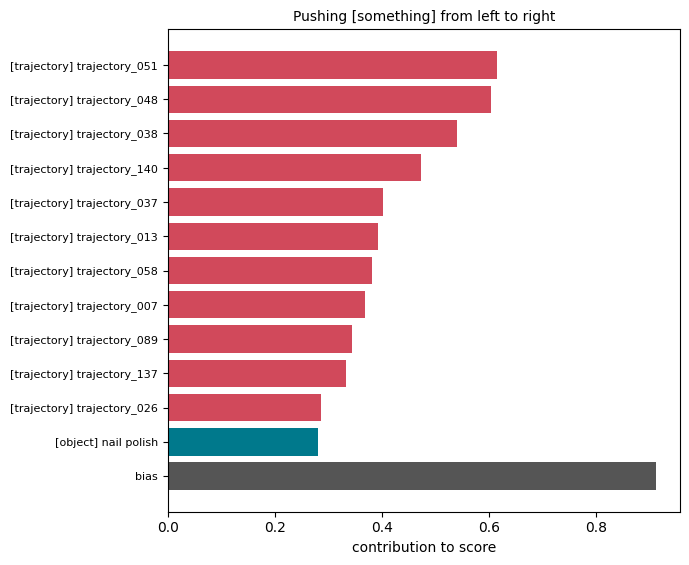

In [3]:
i = 3
e = model.explain(x[i])
print('video:', videos[i])
print('ground truth:', model.classes[labels[i]], '| prediction:', model.classes[e.pred])
print('sum of contributions %.4f + bias %.4f = %.4f (logit %.4f)' % (e.contributions.sum(), e.bias, e.contributions.sum() + e.bias, e.logits[e.pred]))
for g in model.vocab.groups:
    print(g, [(n, round(v, 3)) for _, _, n, v in model.top_concepts(e.contributions, 5, g)])
plot_contributions(model.top_concepts(e.contributions, 12), model.classes[e.pred], extra={'bias': e.bias});

## Intervention

Removing a concept sets its standardized activation to 0 (the training-set mean score). Here we remove the three trajectory concepts with the largest contribution and compare class scores.

In [4]:
top3 = [cid for cid, *_ in model.top_concepts(e.contributions, 3, 'trajectory')]
z = e.activations[None]
z_edit = model.intervene(z, top3, value=0.0)
before, after = model.classify(z)[0], model.classify(z_edit)[0]
for k in torch.argsort(before, descending=True)[:5].tolist():
    print(f'{model.classes[k]:45s} {before[k]:7.3f} -> {after[k]:7.3f}')
print('prediction:', model.classes[int(before.argmax())], '->', model.classes[int(after.argmax())])

Pushing [something] from left to right          7.823 ->   6.062
Pulling [something] from left to right          5.566 ->   4.979
Turning the camera left while filming [something]   2.037 ->   2.037
Pushing [something] from right to left          0.963 ->   0.238
Putting [something similar to other things that are already on the table]   0.556 ->   0.556
prediction: Pushing [something] from left to right -> Pushing [something] from left to right


## Top-K vs. Random-K trajectory-concept removal (paper Table 4 protocol)

K=5: flip top 48.74%  random 3.71%  bottom 0.14%
K=10: flip top 70.14%  random 5.38%  bottom 0.14%


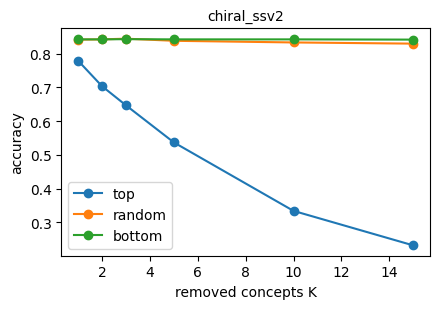

In [5]:
ks = [1, 2, 3, 5, 10, 15]
res = ar_removal(model, x, y, ks=ks, seed=0)
for k in [5, 10]:
    print(f"K={k}: flip top {res[f'top-{k}']['flip_rate']*100:.2f}%  random {res[f'random-{k}']['flip_rate']*100:.2f}%  bottom {res[f'bottom-{k}']['flip_rate']*100:.2f}%")
plot_removal_curve({n: [res[f'{n}-{k}']['acc'] for k in ks] for n in ['top', 'random', 'bottom']}, ks, title=DATASET);

## Trajectory concepts on the video

Each trajectory concept is a FINCH cluster of optical-flow trajectories. The medoid trajectory of each top concept is drawn on the input clip, starting where (Grad-CAM peak) and when the concept responds. Needs the video (`TRACE_VIDEO_ROOT`) and the VideoMAE backbone (`checkpoints/backbones/` or `pretrained/`).

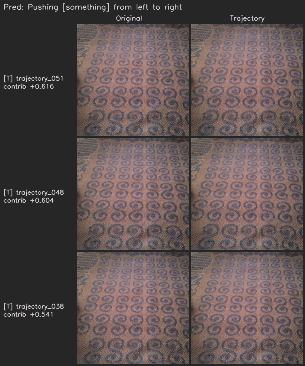

In [6]:
from IPython.display import Image as GIF
if VIDEO_ROOT:
    from src.discovery.trajectory.concepts import load_bundle
    from src.explain.gradcam import videomae_concept_cam
    from src.explain.overlay import concept_overlay_grid, save_animation
    from src.features import videomae
    backbone = videomae.load_videomae(videomae.find_backbone(model.meta['backbone']['checkpoint_file'], '..'), 'cpu')
    clip = videomae.load_clip(os.path.join(VIDEO_ROOT, videos[i]), model.meta['backbone']['sampling'])
    frames = (clip * torch.tensor(videomae.IMAGENET_STD)[:, None, None, None]
              + torch.tensor(videomae.IMAGENET_MEAN)[:, None, None, None]).clamp(0, 1)
    frames = (frames.permute(1, 2, 3, 0).numpy() * 255).round().astype('uint8')
    items = model.top_concepts(e.contributions, 3)
    cams = {c: videomae_concept_cam(backbone, model, clip, c, 'blocks[11].norm1').numpy() for c, g, *_ in items if g == 'trajectory'}
    grid = concept_overlay_grid(frames, items, cams, load_bundle(TRAJ_CONCEPTS)[0], model.vocab, title='Pred: ' + model.classes[e.pred])
    os.makedirs('../outputs', exist_ok=True)
    save_animation(grid, '../outputs/notebook_overlay.mp4')   # full resolution video
    display(GIF(filename=save_animation(grid[:, ::2, ::2], '../outputs/notebook_overlay.gif')))